K-Nearest Neighbors (KNN)

Import library dan membaca dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, f1_score
)
from sklearn.pipeline import Pipeline

df = pd.read_csv("data/WineQT.csv")

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


Mengenal dataset

In [2]:
print("Informasi dataset:")
df.info()

print("\nJumlah nilai kosong:")
print(df.isnull().sum().sum())

print("\nDistribusi kelas quality:")
print(df["quality"].value_counts().sort_index())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB

Jumlah nilai kosong:
0

Distribusi kelas quality:
quality
3      6

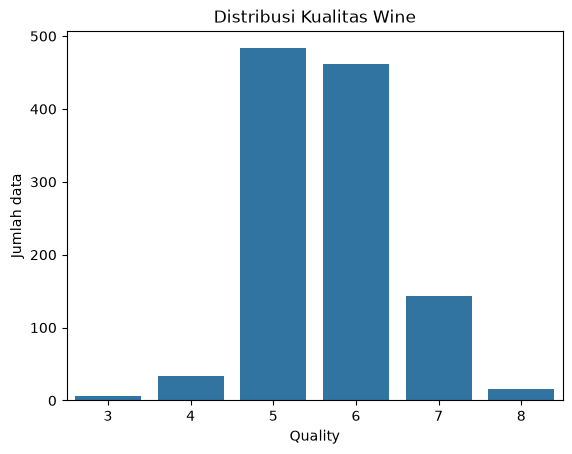

In [3]:
# Visualisasi distribusi target
sns.countplot(data=df, x="quality")
plt.title("Distribusi Kualitas Wine")
plt.xlabel("Quality")
plt.ylabel("Jumlah data")
plt.show()

Menentukan fitur dan target
- X (fitur): karakteristik kimia wine.
- y (target): nilai `quality`.

Kolom `Id` dikeluarkan karena bukan karakteristik yang digunakan untuk menentukan kualitas.

In [4]:
X = df.drop(columns=["quality", "Id"])
y = df["quality"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])

Jumlah fitur: 11
Jumlah data: 1143


Membagi data dan melakukan scaling

Data dibagi menjadi 80% data latih dan 20% data uji. `stratify=y` menjaga proporsi kelas pada kedua bagian. KNN menggunakan perhitungan jarak, sehingga fitur perlu distandardisasi. Pipeline memastikan scaler hanya belajar dari data latih.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

Data latih: (914, 11)
Data uji: (229, 11)


Membuat model KNN

Model pertama menggunakan K=3. Model kedua menggunakan K=5 dengan pembobotan berdasarkan jarak (`weights='distance'`). Pembobotan jarak memberi pengaruh lebih besar kepada tetangga yang lebih dekat.

In [6]:
# Model KNN dengan K=3
knn_3 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=3))
])

knn_3.fit(X_train, y_train)
pred_3 = knn_3.predict(X_test)

print("Evaluasi KNN (K=3)")
print(classification_report(y_test, pred_3, zero_division=0))
print("Accuracy:", round(accuracy_score(y_test, pred_3), 4))
print("Weighted F1:", round(f1_score(y_test, pred_3, average="weighted"), 4))

Evaluasi KNN (K=3)
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.17      0.14      0.15         7
           5       0.73      0.68      0.71        97
           6       0.56      0.67      0.61        92
           7       0.45      0.34      0.39        29
           8       0.00      0.00      0.00         3

    accuracy                           0.61       229
   macro avg       0.32      0.31      0.31       229
weighted avg       0.60      0.61      0.60       229

Accuracy: 0.607
Weighted F1: 0.6


In [7]:
# Model KNN dengan K=5 dan pembobotan jarak
knn_5 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5, weights="distance"))
])

knn_5.fit(X_train, y_train)
pred_5 = knn_5.predict(X_test)

print("Evaluasi KNN (K=5, weights='distance')")
print(classification_report(y_test, pred_5, zero_division=0))
print("Accuracy:", round(accuracy_score(y_test, pred_5), 4))
print("Weighted F1:", round(f1_score(y_test, pred_5, average="weighted"), 4))

Evaluasi KNN (K=5, weights='distance')
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.74      0.73      0.74        97
           6       0.59      0.70      0.64        92
           7       0.54      0.45      0.49        29
           8       0.00      0.00      0.00         3

    accuracy                           0.65       229
   macro avg       0.31      0.31      0.31       229
weighted avg       0.62      0.65      0.63       229

Accuracy: 0.6463
Weighted F1: 0.6296


Confusion matrix

Confusion matrix memperlihatkan jumlah prediksi benar dan salah untuk setiap kelas kualitas wine.

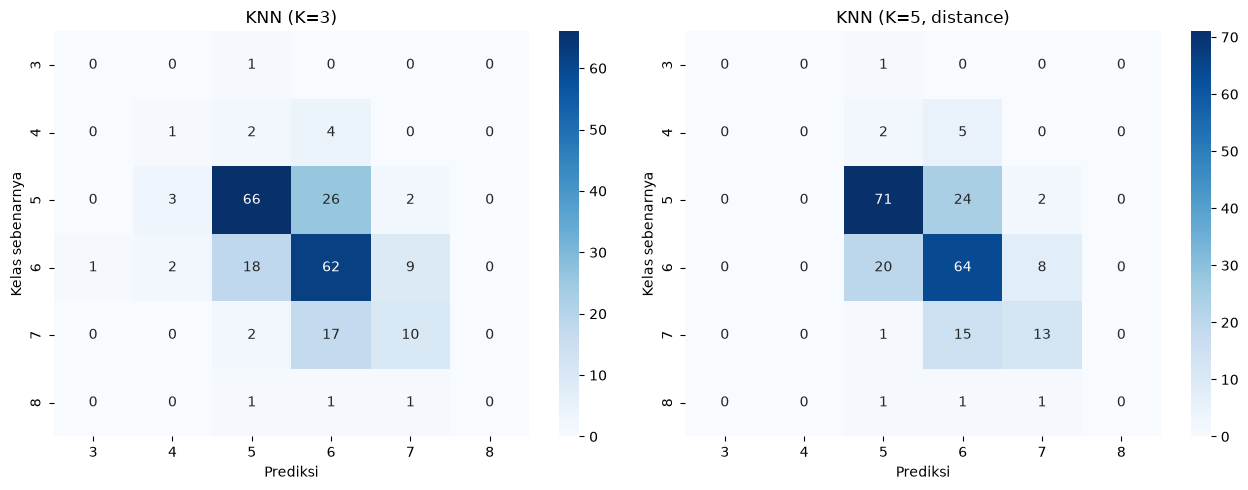

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, y_pred, title in [
    (axes[0], pred_3, "KNN (K=3)"),
    (axes[1], pred_5, "KNN (K=5, distance)")
]:
    cm = confusion_matrix(y_test, y_pred, labels=sorted(y.unique()))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=sorted(y.unique()),
        yticklabels=sorted(y.unique()),
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Kelas sebenarnya")

plt.tight_layout()
plt.show()

Membandingkan beberapa nilai K

Nilai K yang berbeda dapat menghasilkan performa berbeda. Di bawah ini, kita membandingkan weighted F1-score dan error rate (1 − accuracy) untuk K=1 sampai K=20.

In [9]:
hasil = []

for k in range(1, 21):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, weights="distance"))
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    hasil.append({
        "K": k,
        "Weighted F1": f1_score(y_test, pred, average="weighted"),
        "Error Rate": 1 - accuracy_score(y_test, pred)
    })

hasil_df = pd.DataFrame(hasil)
display(hasil_df.round(4))

,K,Weighted F1,Error Rate
0,1,0.6412,0.3493
1,2,0.6412,0.3493
2,3,0.6507,0.3406
3,4,0.6400,0.3450
4,5,0.6296,0.3537
5,6,0.6536,0.3319
6,7,0.6395,0.3450
7,8,0.6510,0.3319
8,9,0.6534,0.3275
9,10,0.6615,0.3188


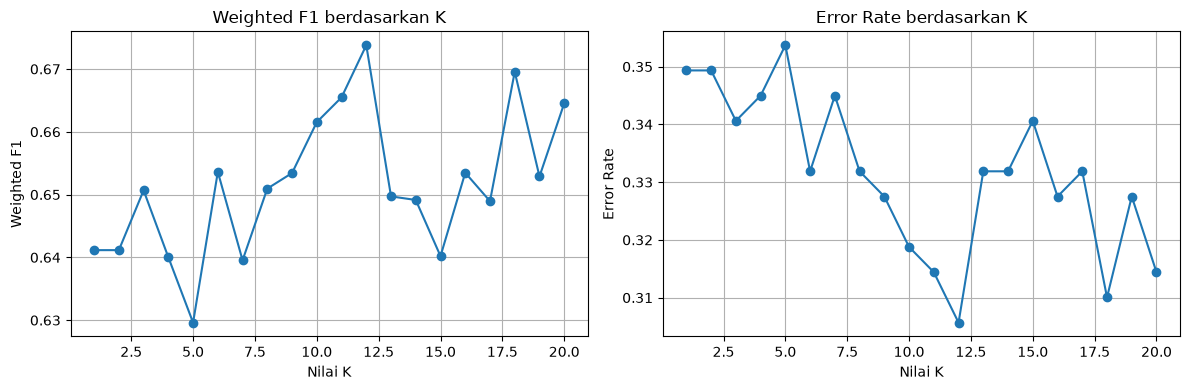

K dengan Weighted F1 tertinggi: 12
Weighted F1: 0.6738


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hasil_df["K"], hasil_df["Weighted F1"], marker="o")
axes[0].set_title("Weighted F1 berdasarkan K")
axes[0].set_xlabel("Nilai K")
axes[0].set_ylabel("Weighted F1")
axes[0].grid(True)

axes[1].plot(hasil_df["K"], hasil_df["Error Rate"], marker="o")
axes[1].set_title("Error Rate berdasarkan K")
axes[1].set_xlabel("Nilai K")
axes[1].set_ylabel("Error Rate")
axes[1].grid(True)

plt.tight_layout()
plt.show()

best_row = hasil_df.loc[hasil_df["Weighted F1"].idxmax()]
print("K dengan Weighted F1 tertinggi:", int(best_row["K"]))
print("Weighted F1:", round(best_row["Weighted F1"], 4))

Sumber Dataset

Kaggle - Wine Quality Dataset

Simpan file sebagai `data/WineQT.csv` sebelum menjalankan notebook.